In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Show every column when we print a table
pd.set_option("display.max_columns", None)

In [2]:

TARGET   = "diagnosis"      # the column we want to predict
# -----------------------------------------------------------------

properties = ["radius", "texture", "perimeter", "area", "smoothness",
              "compactness", "concavity", "concave_points", "symmetry",
              "fractal_dimension"]

COLUMN_NAMES = (
    ["id", "diagnosis"]
    + [f"{p}_mean" for p in properties]
    + [f"{p}_se" for p in properties]
    + [f"{p}_worst" for p in properties]
)

df = pd.read_csv(r"C:\Akshay\Data Analytics\TPM Assignments\Machine Learning\breast+cancer+wisconsin+diagnostic\wdbc.data", header=None, names=COLUMN_NAMES)
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
print("Rows and columns:", df.shape)

print("\nColumn information:")
df.info()

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nNumber of examples in each class:")
print(df[TARGET].value_counts())

Rows and columns: (569, 32)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    f

In [4]:
df.drop(columns=["id", TARGET]).describe().round(2).T.head(12)

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.13,3.52,6.98,11.70,13.37,15.78,28.11
texture_mean,569.0,19.29,4.30,9.71,16.17,18.84,21.80,39.28
perimeter_mean,569.0,91.97,24.30,43.79,75.17,86.24,104.10,188.50
area_mean,569.0,654.89,351.91,143.50,420.30,551.10,782.70,2501.00
smoothness_mean,569.0,0.10,0.01,0.05,0.09,0.10,0.11,0.16
compactness_mean,569.0,0.10,0.05,0.02,0.06,0.09,0.13,0.35
concavity_mean,569.0,0.09,0.08,0.00,0.03,0.06,0.13,0.43
concave_points_mean,569.0,0.05,0.04,0.00,0.02,0.03,0.07,0.20
symmetry_mean,569.0,0.18,0.03,0.11,0.16,0.18,0.20,0.30
fractal_dimension_mean,569.0,0.06,0.01,0.05,0.06,0.06,0.07,0.10


In [5]:
# Cleaning and preparing the data
df = df.drop(columns=["id"])
df[TARGET] = df[TARGET].map({"M": 1, "B": 0})

print("Missing values after mapping:", df[TARGET].isnull().sum())
print("\nClass counts (1 = malignant, 0 = benign):")
print(df[TARGET].value_counts().sort_index())

print("\nShare of each class:")
print(df[TARGET].value_counts(normalize=True).sort_index().round(3))

Missing values after mapping: 0

Class counts (1 = malignant, 0 = benign):
diagnosis
0    357
1    212
Name: count, dtype: int64

Share of each class:
diagnosis
0    0.627
1    0.373
Name: proportion, dtype: float64


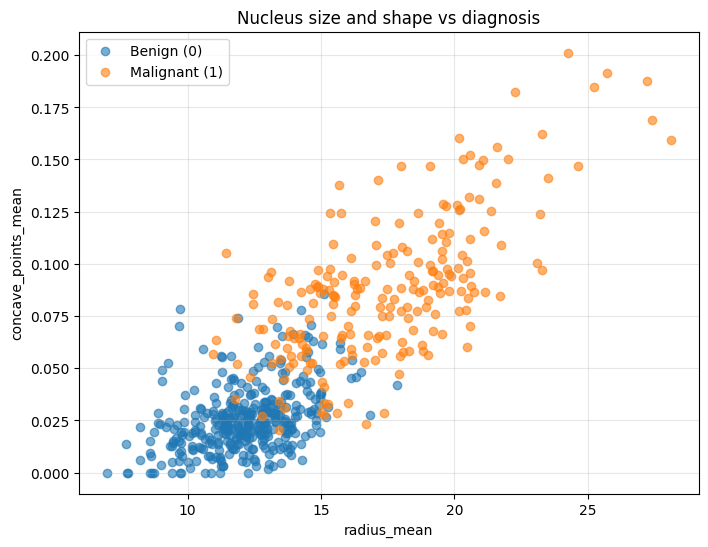

In [6]:
# Visualize the data
plt.figure(figsize=(8, 6))

for label, name in [(0, "Benign (0)"), (1, "Malignant (1)")]:
    subset = df[df[TARGET] == label]
    plt.scatter(
        subset["radius_mean"],
        subset["concave_points_mean"],
        label=name,
        alpha=0.6
    )

plt.title("Nucleus size and shape vs diagnosis")
plt.xlabel("radius_mean")
plt.ylabel("concave_points_mean")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

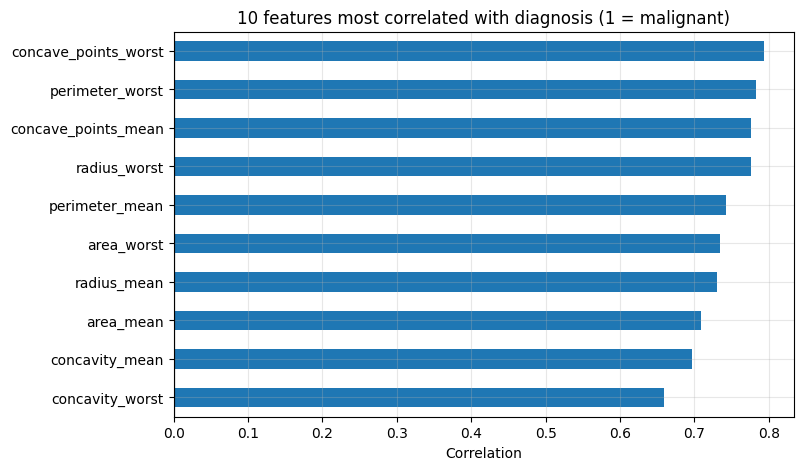

concave_points_worst    0.794
perimeter_worst         0.783
concave_points_mean     0.777
radius_worst            0.776
perimeter_mean          0.743
area_worst              0.734
radius_mean             0.730
area_mean               0.709
concavity_mean          0.696
concavity_worst         0.660
Name: diagnosis, dtype: float64

In [7]:
correlations = df.corr()[TARGET].drop(TARGET)
top = correlations.reindex(correlations.abs().sort_values().index).tail(10)

plt.figure(figsize=(8, 5))
top.plot(kind="barh")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("10 features most correlated with diagnosis (1 = malignant)")
plt.xlabel("Correlation")
plt.grid(True, alpha=0.3)
plt.show()

top.sort_values(ascending=False).round(3)

### 

- **malignant samples (1) sit towards larger nuclei with more concave points**, while benign samples (0) cluster at smaller sizes and fewer concave points.

In [8]:
# Separati the input features (X) and the target (y)
X = df.drop(columns=[TARGET])
y = df[TARGET]

print("Number of input features:", X.shape[1])
display(X.iloc[:, :6].head())

print("Target labels:")
display(y.head())

Number of input features: 30


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean
0,17.99,10.38,122.80,1001.0,0.11840,0.27760
1,20.57,17.77,132.90,1326.0,0.08474,0.07864
2,19.69,21.25,130.00,1203.0,0.10960,0.15990
3,11.42,20.38,77.58,386.1,0.14250,0.28390
4,20.29,14.34,135.10,1297.0,0.10030,0.13280


Target labels:


0    1
1    1
2    1
3    1
4    1
Name: diagnosis, dtype: int64

In [9]:
#  training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training examples:", len(X_train))
print("Testing examples: ", len(X_test))

print("\nTraining class counts:")
print(y_train.value_counts().sort_index())
print("\nTesting class counts:")
print(y_test.value_counts().sort_index())

Training examples: 455
Testing examples:  114

Training class counts:
diagnosis
0    285
1    170
Name: count, dtype: int64

Testing class counts:
diagnosis
0    72
1    42
Name: count, dtype: int64


In [10]:
# first model (Logistic Regression)
log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
log_model.fit(X_train, y_train)

print("Classification model trained!")

# which features push the prediction towards each class
coefs = pd.Series(
    log_model.named_steps["logisticregression"].coef_[0],
    index=X.columns
).sort_values()

print("\nFeatures pushing towards BENIGN (most negative coefficients):")
display(coefs.head(5).round(3))

print("Features pushing towards MALIGNANT (most positive coefficients):")
display(coefs.tail(5).round(3))

Classification model trained!

Features pushing towards BENIGN (most negative coefficients):


compactness_se         -0.907
fractal_dimension_se   -0.594
compactness_mean       -0.440
texture_se             -0.408
symmetry_se            -0.331
dtype: float64

Features pushing towards MALIGNANT (most positive coefficients):


concavity_worst        0.911
concave_points_mean    0.953
symmetry_worst         1.061
radius_se              1.233
texture_worst          1.434
dtype: float64

In [11]:
# Prediction of classes and probabilities
y_pred = log_model.predict(X_test)
probabilities = log_model.predict_proba(X_test)

results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred,
    "Probability_Malignant": probabilities[:, list(log_model.classes_).index(1)].round(3)
})
results["Correct?"] = np.where(results["Actual"] == results["Predicted"], "yes", "NO")

results.sort_index().head(10)

,Actual,Predicted,Probability_Malignant,Correct?
4,1,1,1.000,yes
5,1,1,0.883,yes
7,1,1,0.954,yes
14,1,1,0.902,yes
20,0,0,0.002,yes
22,1,1,0.991,yes
34,1,1,0.998,yes
39,1,1,0.762,yes
60,0,0,0.000,yes
64,1,1,0.997,yes


In [12]:
# identifying samples where the model got wrong
wrong = results[results["Actual"] != results["Predicted"]]
print("Number of mistakes on the test set:", len(wrong))
wrong.sort_index()

Number of mistakes on the test set: 4


,Actual,Predicted,Probability_Malignant,Correct?
73,1,0,0.061,NO
190,1,0,0.315,NO
205,1,0,0.492,NO
455,0,1,0.509,NO


In [13]:
# Model Evaluation
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

#  most common class seen
baseline_accuracy = (y_test == y_train.mode()[0]).mean()

print(f"Accuracy:                         {accuracy:.2%}")
print(f"Baseline accuracy (always benign): {baseline_accuracy:.2%}")

print("\nConfusion matrix (rows = actual, columns = predicted):")
print(cm)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Benign (0)", "Malignant (1)"],
    zero_division=0
))

Accuracy:                         96.49%
Baseline accuracy (always benign): 63.16%

Confusion matrix (rows = actual, columns = predicted):
[[71  1]
 [ 3 39]]

Classification report:
               precision    recall  f1-score   support

   Benign (0)       0.96      0.99      0.97        72
Malignant (1)       0.97      0.93      0.95        42

     accuracy                           0.96       114
    macro avg       0.97      0.96      0.96       114
 weighted avg       0.97      0.96      0.96       114



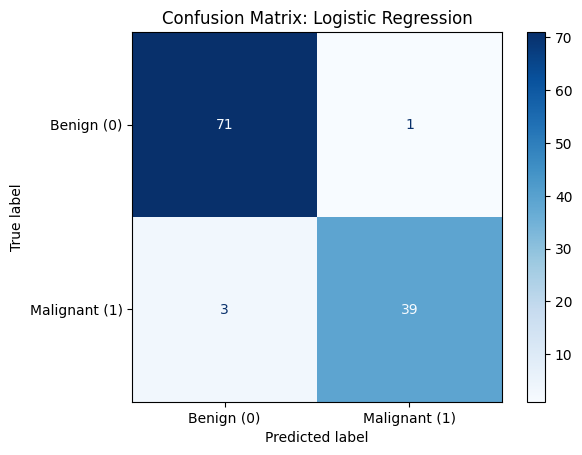

In [14]:
# Visualization of a matrix
display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign (0)", "Malignant (1)"]
)
display_cm.plot(cmap="Blues")
plt.title("Confusion Matrix: Logistic Regression")
plt.grid(False)
plt.show()

In [15]:
# Random Forest Model
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

baseline_pred = np.full(len(y_test), y_train.mode()[0])

def summarize(name, y_true, y_hat):
    return {
        "Model": name,
        "Accuracy":  accuracy_score(y_true, y_hat),
        "Precision": precision_score(y_true, y_hat, zero_division=0),
        "Recall":    recall_score(y_true, y_hat, zero_division=0),
        "F1":        f1_score(y_true, y_hat, zero_division=0),
    }

comparison = pd.DataFrame([
    summarize("Baseline (always benign)", y_test, baseline_pred),
    summarize("Logistic Regression",      y_test, y_pred),
    summarize("Random Forest",            y_test, y_pred_rf),
]).round(3)

comparison

,Model,Accuracy,Precision,Recall,F1
0,Baseline (always benign),0.632,0.000,0.000,0.000
1,Logistic Regression,0.965,0.975,0.929,0.951
2,Random Forest,0.965,1.000,0.905,0.950


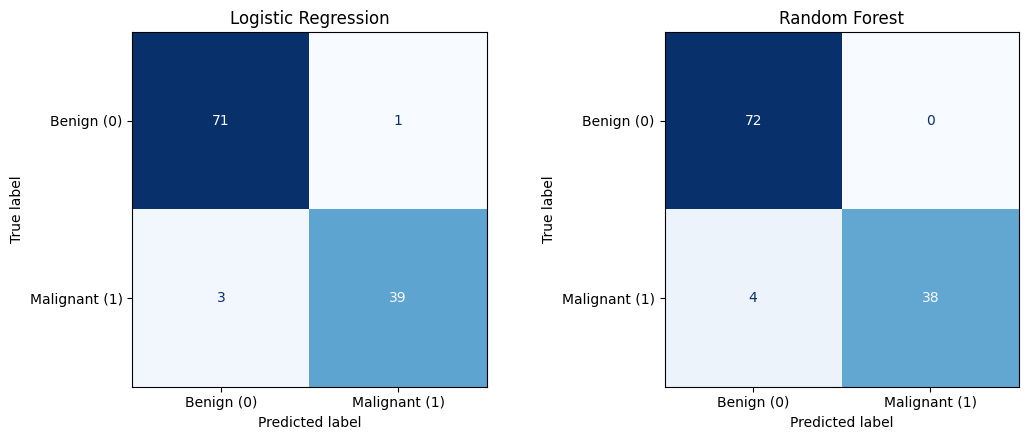

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, pred, name in zip(axes, [y_pred, y_pred_rf], ["Logistic Regression", "Random Forest"]):
    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_test, pred, labels=[0, 1]),
        display_labels=["Benign (0)", "Malignant (1)"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.grid(False)

plt.tight_layout()
plt.show()

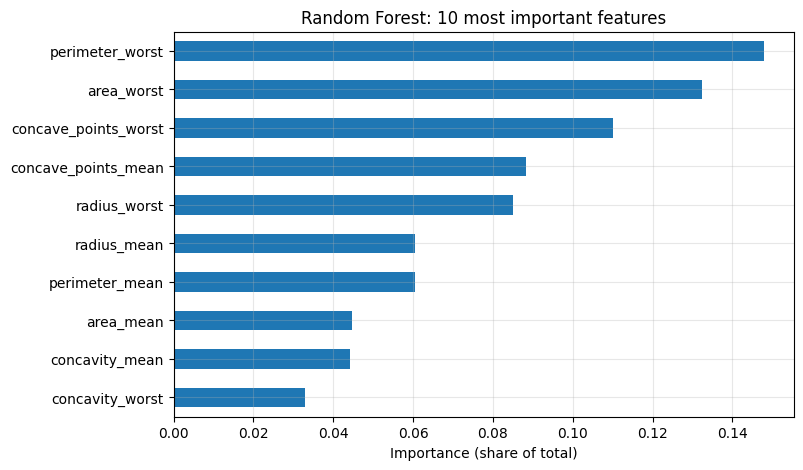

perimeter_worst         0.148
area_worst              0.132
concave_points_worst    0.110
concave_points_mean     0.088
radius_worst            0.085
radius_mean             0.061
perimeter_mean          0.060
area_mean               0.045
concavity_mean          0.044
concavity_worst         0.033
dtype: float64

In [17]:
importance = pd.Series(rf_model.feature_importances_, index=X.columns)
top_importance = importance.sort_values().tail(10)

plt.figure(figsize=(8, 5))
top_importance.plot(kind="barh")
plt.title("Random Forest: 10 most important features")
plt.xlabel("Importance (share of total)")
plt.grid(True, alpha=0.3)
plt.show()

importance.sort_values(ascending=False).head(10).round(3)

In [18]:
# classification threshold
test_probabilities = log_model.predict_proba(X_test)[:, list(log_model.classes_).index(1)]

rows = []
for threshold in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred_t = (test_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_t, labels=[0, 1]).ravel()
    rows.append({
        "Threshold": threshold,
        "False alarms (FP)": fp,
        "Missed cancers (FN)": fn,
        "Precision": round(precision_score(y_test, pred_t, zero_division=0), 3),
        "Recall": round(recall_score(y_test, pred_t, zero_division=0), 3),
    })

pd.DataFrame(rows)

,Threshold,False alarms (FP),Missed cancers (FN),Precision,Recall
0,0.1,5,1,0.891,0.976
1,0.3,1,1,0.976,0.976
2,0.5,1,3,0.975,0.929
3,0.7,0,4,1.000,0.905
4,0.9,0,9,1.000,0.786


In [19]:
# Testing new sample

new_case = X_test.iloc[[0]].copy()      # one sample, kept as a one-row table
# new_case["radius_mean"] = 15.0        # <- uncomment and edit to try your own values

predicted_class = log_model.predict(new_case)[0]
malignant_probability = log_model.predict_proba(new_case)[0, list(log_model.classes_).index(1)]

print("Predicted class:", predicted_class)
print("Estimated probability of malignant:", f"{malignant_probability:.1%}")

if predicted_class == 1:
    print("Model prediction: Likely malignant")
else:
    print("Model prediction: Likely benign")

print("\nRandom Forest prediction:", rf_model.predict(new_case)[0])
print("Known diagnosis for this sample:", y_test.iloc[0])

Predicted class: 0
Estimated probability of malignant: 0.0%
Model prediction: Likely benign

Random Forest prediction: 0
Known diagnosis for this sample: 0
